# Módulo 02 · Visão geral e dados

**Retina em Foco — Processamento Digital de Imagens Biomédicas** · IFPE Campus Palmares · Formação Técnica 2026.2

Este projeto reúne os notebooks das seis etapas da ementa do Módulo 02. O fio condutor é o caminho de uma
retinografia **da captura até o tensor que entra no modelo de IA** (MobileNetV3-Small / EfficientNet-Lite0, Módulo 4):

```
captura ─▶ controle de qualidade ─▶ campo de visão (FOV) ─▶ realce (CLAHE) ─▶ redimensionar/normalizar ─▶ modelo
  01              05                        02                     03                    06
                                   segmentação (04): entender o que há na imagem
```

| Notebook | Item da ementa | O que você vai fazer |
|---|---|---|
| `01_Aquisicao_de_Imagens` | 01 · Aquisição de imagens de fundo de olho | do fóton ao pixel; resolução, profundidade de bits, compressão; foco e iluminação como números |
| `02_OpenCV_e_Espacos_de_Cor` | 02 · OpenCV e espaços de cor | RGB×BGR, canais, HSV/LAB/YCrCb, máscara do campo de visão; por que o canal verde |
| `03_Filtragem_e_CLAHE` | 03 · Filtragem e realce de contraste | suavização, nitidez, equalização, CLAHE e seus parâmetros, correção de iluminação |
| `04_Segmentacao_Estruturas_Retinianas` | 04 · Segmentação | vasos (Frangi, avaliação contra padrão-ouro), disco óptico, candidatos a lesões |
| `05_Avaliacao_Qualidade_Imagem` | 05 · Avaliação automática da qualidade | métricas, calibração de limiares, degradações sintéticas, ROC |
| `06_Preparacao_para_Inferencia` | 06 · Preparação de imagens para inferência | recorte, redimensionamento, normalização, fluxo completo e latência |

> **Como usar:** execute as células na ordem. Cada notebook termina com **exercícios propostos** — são a base da
> entrega "Exercícios de programação" (filtragem, CLAHE e segmentação) avaliada no AVEA.

## 1. Verificando o ambiente

In [1]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from retina_pdi import dados, pipeline as P, visualizacao as V

V.configurar_estilo()
print(f"OpenCV {cv2.__version__} | NumPy {np.__version__} | pandas {pd.__version__}")

OpenCV 4.14.0 | NumPy 2.5.3 | pandas 3.0.6


In [2]:
import sys, platform
print("Python      :", sys.version.split()[0], "|", platform.system())
print("Raiz projeto:", dados.RAIZ)
print("Manifesto   :", "ok" if dados.MANIFESTO.exists() else "AUSENTE — rode:  python scripts/download_data.py")

Python      : 3.12.10 | Windows
Raiz projeto: C:\Users\Tiago Lima\OneDrive\Projetos\Editais\Aprovados\COMPET\Fase 1\Módulo 2
Manifesto   : ok


## 2. As imagens do projeto

Todas são retinografias **reais e públicas**, baixadas por `scripts/download_data.py`. O arquivo `data/manifest.csv`
lista cada imagem, sua condição, fonte, licença e (no HRF) as máscaras de referência.

In [3]:
m = dados.carregar_manifesto()
print(f"{len(m)} imagens · {m.fonte.nunique()} fontes")
m[["id", "fonte", "condicao", "rotulo_original", "largura", "altura", "licenca"]].head(8)

115 imagens · 3 fontes


,id,fonte,condicao,rotulo_original,largura,altura,licenca
0,hrf_01_g,HRF,glaucoma,g,3504,2336,CC BY 4.0
1,hrf_02_g,HRF,glaucoma,g,3504,2336,CC BY 4.0
2,hrf_03_g,HRF,glaucoma,g,3504,2336,CC BY 4.0
3,hrf_04_g,HRF,glaucoma,g,3504,2336,CC BY 4.0
4,hrf_05_g,HRF,glaucoma,g,3504,2336,CC BY 4.0
5,hrf_06_g,HRF,glaucoma,g,3504,2336,CC BY 4.0
6,hrf_07_g,HRF,glaucoma,g,3504,2336,CC BY 4.0
7,hrf_08_g,HRF,glaucoma,g,3504,2336,CC BY 4.0


In [4]:
tabela = m.pivot_table(index="fonte", columns="condicao", values="id", aggfunc="count", fill_value=0)
tabela = tabela[[c for c in dados.CONDICOES if c in tabela.columns]]
tabela["total"] = tabela.sum(axis=1)
tabela.loc["TOTAL"] = tabela.sum()
tabela

condicao,normal,rd,glaucoma,dmri,total
fonte,,,,,
HRF,15,15,15,0,45
ODIR,8,10,12,12,42
RFMiD,8,4,8,8,28
TOTAL,31,29,35,20,115


| Fonte | O que é | Resolução | Licença / uso | Por que está aqui |
|---|---|---|---|---|
| **HRF** | High-Resolution Fundus (FAU Erlangen): 15 saudáveis, 15 RD, 15 glaucoma | 3504×2336 | CC BY 4.0 | alta resolução e **segmentação manual de vasos** + máscara do FOV → permite *medir* filtros e segmentações |
| **RFMiD** | Retinal Fundus Multi-disease Image Dataset (Pachade et al., 2021) | ≈2144×1424 | CC BY 4.0 | resolução clínica; contém **DMRI**, RD e escavação do disco (sinal sugestivo de glaucoma) |
| **ODIR** | Ocular Disease Intelligent Recognition (ODIR-5K) | 512×512 | uso educacional/pesquisa | diversidade de câmeras e **qualidade real bem variada** (ótima para o notebook 05) |

Os bancos de treinamento citados no edital (Messidor-2, APTOS 2019, DDR, REFUGE, ADAM) serão usados no **Módulo 4**;
aqui trabalhamos com amostras pequenas para que tudo rode em qualquer laptop (e, depois, no Raspberry Pi).

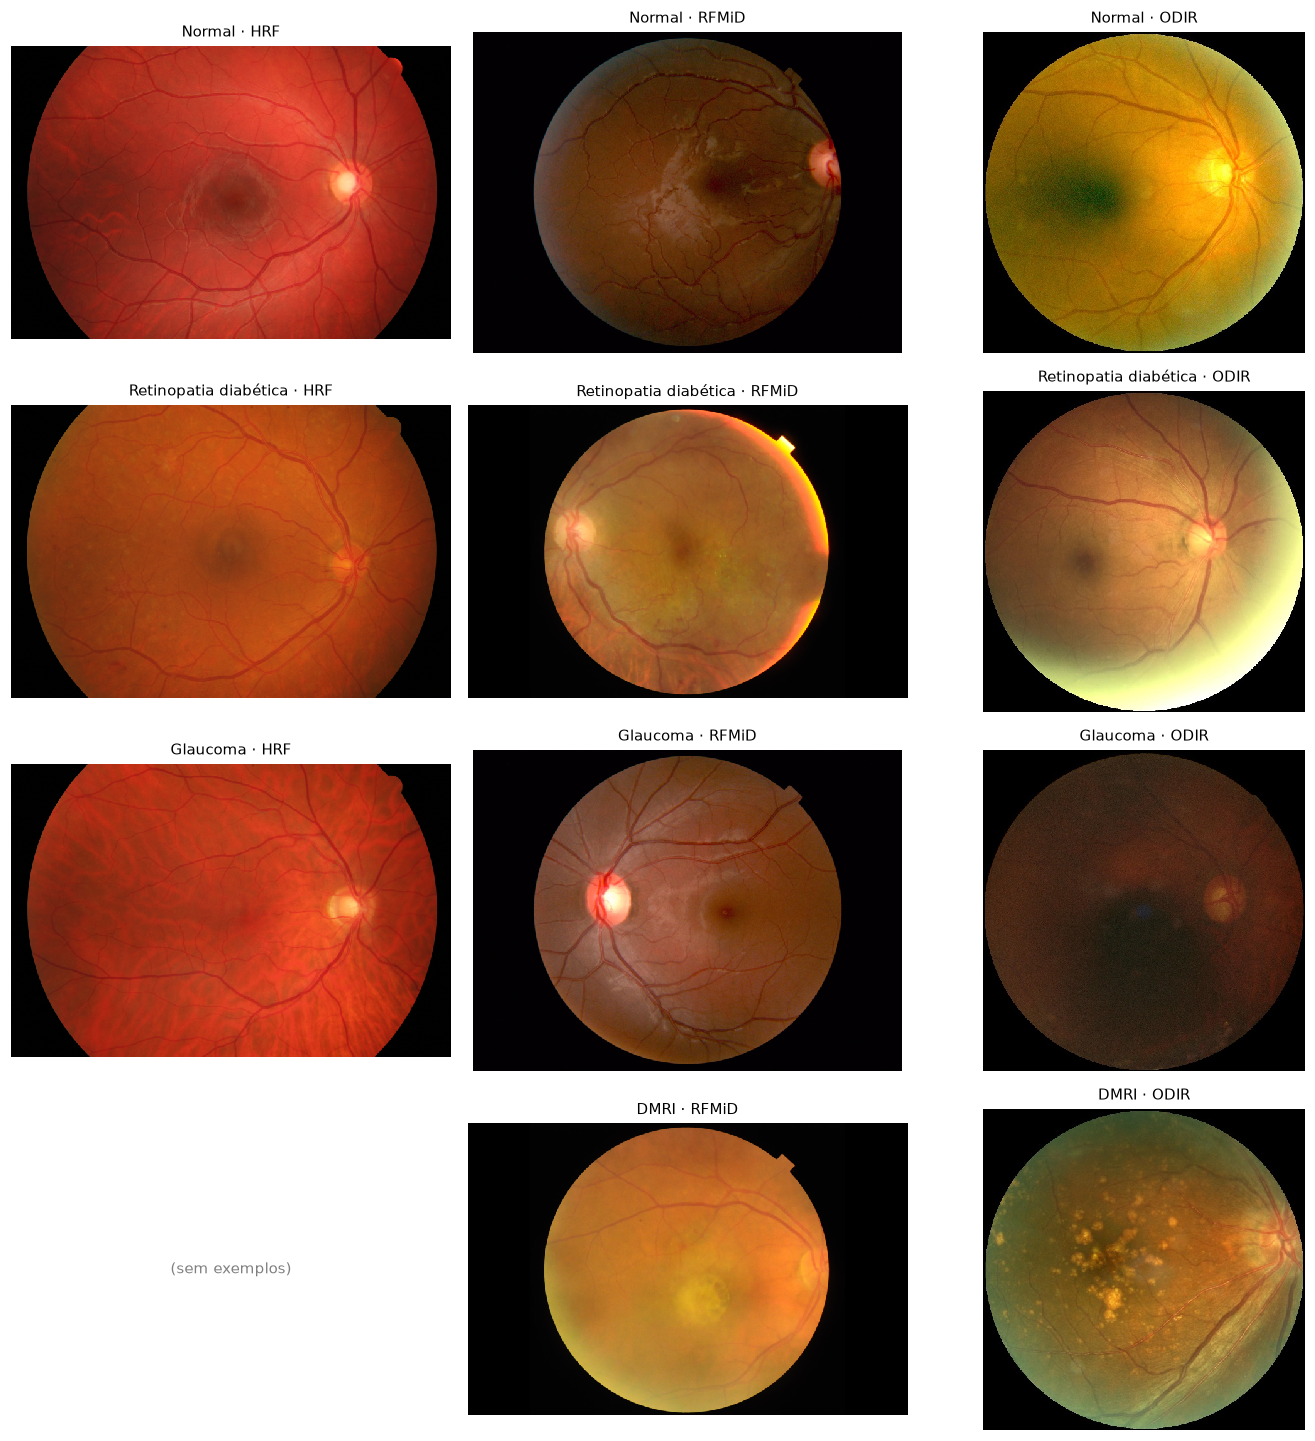

In [5]:
fontes = ["HRF", "RFMiD", "ODIR"]
fig, axs = plt.subplots(len(dados.CONDICOES), len(fontes), figsize=(4.2 * len(fontes), 3.3 * len(dados.CONDICOES)))
for i, c in enumerate(dados.CONDICOES):
    for j, f in enumerate(fontes):
        ax = axs[i, j]; ax.axis("off")
        sel = dados.selecionar(c, f, n=1, seed=3)
        if len(sel):
            ax.imshow(dados.reduzir(dados.carregar_rgb(sel.iloc[0].arquivo), 700))
            ax.set_title(f"{dados.NOMES_CONDICAO[c]} · {f}")
        else:
            ax.text(0.5, 0.5, "(sem exemplos)", ha="center", va="center", color="gray"); 
fig.tight_layout()
V.salvar_figura(fig, "00_galeria_condicoes_fontes")
plt.show()

In [6]:
res = m.groupby("fonte").agg(imagens=("id", "count"), largura=("largura", "median"), altura=("altura", "median"))
res["megapixels"] = res.largura * res.altura / 1e6
res.round(2)

,imagens,largura,altura,megapixels
fonte,,,,
HRF,45,3504.0,2336.0,8.19
ODIR,42,512.0,512.0,0.26
RFMiD,28,2048.0,1536.0,3.15


## 3. Cuidados ao interpretar estes dados

* **Rótulos herdados.** Os rótulos (RD, glaucoma, DMRI, normal) vêm de cada base pública; **não foram revistos** por oftalmologista neste projeto.
  Use-os como "condição declarada pela fonte".
* **"Glaucoma" no RFMiD = escavação do disco óptico (ODC)**, um *sinal sugestivo* de glaucoma — não um diagnóstico.
  No HRF e no ODIR o rótulo é o da própria base.
* **Sem verdade de "qualidade".** Nenhuma base traz rótulo confiável de qualidade de captura; por isso o notebook 05 valida
  os avaliadores com **degradações sintéticas de intensidade conhecida** e inspeção visual das reprovadas.
* **Câmeras diferentes = cores e resolução diferentes.** Isto não é um detalhe: é o principal risco de generalização
  dos modelos (veremos no notebook 02) e o motivo de *calibrar os limiares de qualidade no próprio retinógrafo*.
* **Ética e licenças.** São imagens públicas e anonimizadas; o projeto usa apenas bases públicas e ensaios de bancada
  (sem procedimentos com humanos, portanto sem submissão ao CEP — Edital nº 14/2026, §2.3.2). Respeite a licença e cite as fontes
  (`docs/DADOS.md`).

## 4. Convenções do código

| Objeto | Convenção |
|---|---|
| imagem colorida | `numpy.ndarray` `uint8`, formato **H × W × 3**, ordem **RGB** (o OpenCV usa BGR — veja o notebook 02) |
| máscara | `numpy.ndarray` `bool`, **H × W** |
| carregar | `dados.carregar_rgb(caminho)` (funciona com acentos no caminho, ao contrário de `cv2.imread` no Windows) |
| selecionar | `dados.selecionar(condicao, fonte, n, seed)` → linhas do manifesto |
| pacote | `retina_pdi.pipeline` (funções finais), `.qualidade`, `.degradacoes`, `.fluxo`, `.visualizacao` |

## 5. Onde este módulo toca as metas do projeto (Tabela 3 do edital)

| Meta do edital | Onde é trabalhada |
|---|---|
| ≥ 80 % das capturas com qualidade adequada à leitura | notebook **05** (métricas + limiares) |
| ≤ 3 s por condição e RAM ≤ 512 MB por inferência | notebook **06** (orçamento de tempo do pré-processamento) |
| Fluxo embarcado de aquisição, controle de qualidade e pré-processamento (Fase 2, atividade 3) | `retina_pdi.fluxo.processar_captura` — insumo da Frente **F2** |